# Optimization with a graph surrogate

Below is shown how an SBArchOpt problem can be optimized using a graph-based surrogate. The variables are processor count `n = 1 or 2` and common size `s in [0, 1]`. The objective `(n * s - 1.4)**2 + 0.1 * n` penalizes capacity error and processor count; its minimum is 0.2 for two processors of size 0.7. The code requires SBArchOpt's graph-surrogate support and the `arch_sbo` and notebook dependencies.

In [1]:
from operator import itemgetter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from pymoo.core.variable import Integer, Real
from pymoo.optimize import minimize

from sb_arch_opt.problem import ArchOptProblemBase
from sb_arch_opt.algo.arch_sbo import get_sbo
from sb_arch_opt.algo.arch_sbo.graph import (
    CompositeGraphKernel, GraphRepresentation, LdWloa, NodeLabeling,
    SizingFeature, SizingKernel,
)
from sb_arch_opt.algo.arch_sbo.infill import get_default_infill
from sb_arch_opt.algo.arch_sbo.models import ModelFactory

SEED = 42
N_INIT = 10
BATCH_SIZE = 2
MAX_EVALS = 24

## Defining the Optimization Problem

`ArchOptProblemBase` declares the design variables, and `_arch_evaluate` calculates objective values for a batch of designs. Both variables are always active. `_gen_all_discrete_x` lists the two processor-count choices; the sampler varies the continuous size when generating designs.

In [2]:
class ProcessorProblem(ArchOptProblemBase):
    def __init__(self):
        super().__init__([
            Integer(bounds=(1, 2)),
            Real(bounds=(0.0, 1.0)),
        ])

    def _is_conditionally_active(self):
        return [False, False]

    def _get_n_valid_discrete(self):
        return 2

    def _gen_all_discrete_x(self):
        x = np.array([[1, 0.5], [2, 0.5]])
        return x, np.ones(x.shape, dtype=bool)

    def _arch_evaluate(self, x, is_active_out, f_out, g_out, h_out, *args, **kwargs):
        n_processors, size = x.T
        f_out[:, 0] = (n_processors * size - 1.4)**2 + 0.1 * n_processors


problem = ProcessorProblem()

## Representing Designs as Graphs

The custom decoder creates a system node and one node per processor. Each node is identified by its role and instance index; constant and role labelings exclude the index. The `GraphDecoder` interface provides `labelings`, `sizing_features`, and `decode(x)`. Each decoded representation contains a graph, its node labels, and its sizing values. The size already lies in [0, 1] and needs no further scaling.

In [3]:
class ProcessorDecoder:
    def __init__(self):
        self.constant_labeling = NodeLabeling("processor.constant", self._constant_label)
        self.role_labeling = NodeLabeling("processor.role", itemgetter(0))
        self.sizing_features = (SizingFeature("processor_size", "numeric"),)

    @staticmethod
    def _constant_label(node):
        return "node"

    @property
    def labelings(self):
        return self.constant_labeling, self.role_labeling

    def decode(self, x):
        representations = []
        for n_processors, size in x:
            graph = nx.DiGraph()
            system = ("system", 0)
            graph.add_node(system)
            for index in range(int(n_processors)):
                graph.add_edge(system, ("processor", index), kind="contains")

            representations.append(GraphRepresentation(
                graph=graph,
                node_labels={
                    labeling: {node: labeling(node) for node in graph}
                    for labeling in self.labelings
                },
                sizing_values=np.array([size]),
            ))
        return representations


decoder = ProcessorDecoder()

## Constructing the Graph Surrogate

`LdWloa` compares labeled graphs at depths 0, 1, and 2, while `SizingKernel` compares processor sizes. Their contributions are learned during training. The composite combines structure, sizing, and their product; `ModelFactory` creates the surrogate and input normalization.

In [4]:
# Define a hybrid graph / sizing kernel
kernel = CompositeGraphKernel(
    branches=[
        LdWloa(cutoff=2, labelings=decoder.labelings),
        SizingKernel(decoder.sizing_features),
    ],
    composition="additive_interaction",
)

# Factory returns the graph surrogate that uses the specified kernels
surrogate, normalization = ModelFactory(problem).get_graph_kriging_model(
    decoder=decoder,
    kernel=kernel,
    multi=False,
    seed=SEED,
    n_start=1,
)

## Running the Optimization

`get_default_infill` selects the acquisition criterion, and `get_sbo` combines it with the surrogate. The run starts with ten evaluations and adds two designs per infill batch, stopping after 24 evaluations.

In [5]:
# Get the infill criterion
infill, _ = get_default_infill(problem, n_parallel=BATCH_SIZE)

# Define the SBO algorithm that uses the hybrid graph / sizing surrogate
algorithm = get_sbo(
    surrogate_model=surrogate,
    infill=infill,
    init_size=N_INIT,
    infill_size=BATCH_SIZE,
    infill_pop_size=30,
    infill_gens=10,
    normalization=normalization,
)
result = minimize(
    problem, algorithm,
    termination=("n_evals", MAX_EVALS),
    seed=SEED,
    verbose=False,
)

## Inspecting the Result

The returned design vector gives the processor count and size. Compare it with the known optimum of two processors of size 0.7. The plot shows the best objective observed as evaluations accumulate; the dashed line marks the minimum of 0.2.

Processors: 2; size: 0.700
Best objective: 0.2000; known optimum: 0.2000


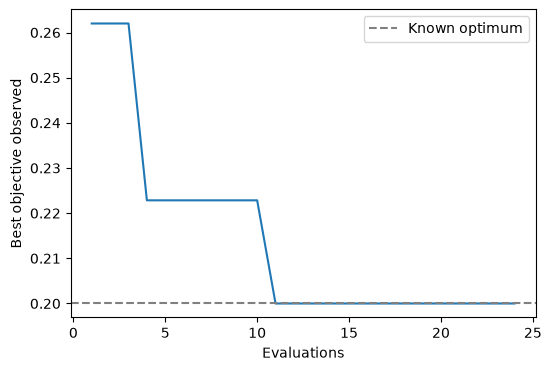

In [6]:
best_x = result.X
print(f"Processors: {int(best_x[0])}; size: {best_x[1]:.3f}")
print(f"Best objective: {result.F[0]:.4f}; known optimum: 0.2000")

values = result.pop.get("F")[:, 0]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(values) + 1), np.minimum.accumulate(values))
ax.axhline(0.2, color="grey", linestyle="--", label="Known optimum")
ax.set(xlabel="Evaluations", ylabel="Best objective observed")
ax.legend()
plt.show()